# Google tunable coupler: a 2 × 2 lattice (four qubits, four couplers), a Quantcore-PDK rebuild, step by step

**What the chip is.** The smallest closed plaquette of Sycamore's coupler lattice: four flux-tunable Xmon-type
transmons on the corners of a square, a flux-tunable transmon coupler on each of the four bonds (Yan et al., PR Applied
10, 054062 (2018); Arute et al., Nature 574, 505 (2019)). Every qubit has a λ/4 readout, an XY line and a Z line; every
coupler a Z line. It is the cell of `google_tc_cell` (same qubit, coupler, junctions and coupling geometry) tiled round
a square.

**This notebook rebuilds the plaquette in the Quantcore PDK; it is not a replica** (spec
`docs/designs/google/google_tc_2x2.md`): Quantum Metal `TransmonCrossFL` crosses with **Quantcore trilayer SQUIDs**
(PDK junction rule), Quantcore `BondPad`s, qcc routes and a KQC airbridge where a coupler's Z line crosses a feedline,
the PDK die frame (10 × 10 mm, QCT), sapphire 650 µm (εr 10.25), and the qcc LOM.

| | from the source | adapted here (why) |
|---|---|---|
| lattice | square grid, a coupler on every nearest-neighbour bond (Sycamore: 54 qubits, 88 couplers, diagonal array) | the 2 × 2 plaquette, axis-aligned |
| qubits, coupler, couplings | as `google_tc_cell` (Sycamore SI Table 2, §I; Yan Fig. 2, Eq. 5) | the same cross sizes, SQUIDs, end-on gaps and `d.couple` estimates |
| idle frequencies | Sycamore idles neighbours apart | checkerboard: Q00 / Q11 at the design L_J, Q10 / Q01 detuned by L_J (LOM only) |
| readout | 9 groups of 6 qubits on Purcell-filtered lines | two feedlines (left: Q00, Q01; right: Q10, Q11), λ/4 hangers at 4.56 … 4.68 GHz, no Purcell filter |
| wiring | flip-chip wiring die, bump bonds | planar: the two side couplers' Z lines cross the feedlines on airbridges |
| junctions | Al/AlOx SQUIDs (not given) | Quantcore Nb/AlOx/Nb trilayer SQUIDs (PDK rule: Δ 1.4 meV, R_n 40–50 kΩ) |
| pads | (no layout) | **PDK pad rule**: 16 bond pads, each etch `frame.pad_edge` = 100 µm from the die edge (`edge="auto"`) |
| placement | (no layout) | the plaquette sits at the die centre (checked in step 6) |
| cheese | (no layout to take it from) | **PDK band** (`cheese: "auto"`): no original cheese exists |

**Licences.** Papers cited for parameters only; the layout and code are ours (GPL, as the repository).

## 1 · Setup and the PDK

The notebook runs from the repository root; `_common` holds the table, snapshot, coupling and PDK helpers. `LIVE`
follows `QCC_LIVE` (live KLayout, or headless snapshots with `QCC_LIVE=0`).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, coupling and PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj
from quantcore_circuits.lom import estimates as est
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/google")
EPS = est.substrate_eps(get_pdk())               # sapphire, εr 10.25

The PDK facts this chip relies on; the library applies each of them (frame and cheese in the build, the pad rule
through `edge=`, the junctions through `trilayer_junction`, the margins as DRC design warnings).

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**Source targets** (Arute et al. 2019, SI Table 2 and §I), the readout plan (staggered round Sycamore's median) and the
λ/4 lengths, set for those frequencies with the LOM.

In [3]:
SRC = {"f_q_idle_GHz": 6.661, "alpha_MHz": -208.0, "f_r_GHz": 4.618, "kappa_MHz": 0.64, "g_on_MHz": -20.0}
F_R = {"Q00": 4.56, "Q01": 4.60, "Q10": 4.64, "Q11": 4.68}           # staggered readouts around 4.618 GHz
L_READ = {"Q00": 6243, "Q01": 6182, "Q10": 6122, "Q11": 6064}       # λ/4 lengths, set for F_R with the LOM

## 2 · The die and the frame

A 10 × 10 mm die: the plaquette needs sixteen pads. The build draws the PDK frame (dicing L's, alignment grids, chip
boundary, the device ID `GTC4Q` on a free edge).

The layout is written for the bottom-left quadrant and mirrored: `M(sx, sy)` maps a bottom-left point into the
quadrant (sx, sy) = (±1, ±1) round the plaquette centre (X0, Y0).

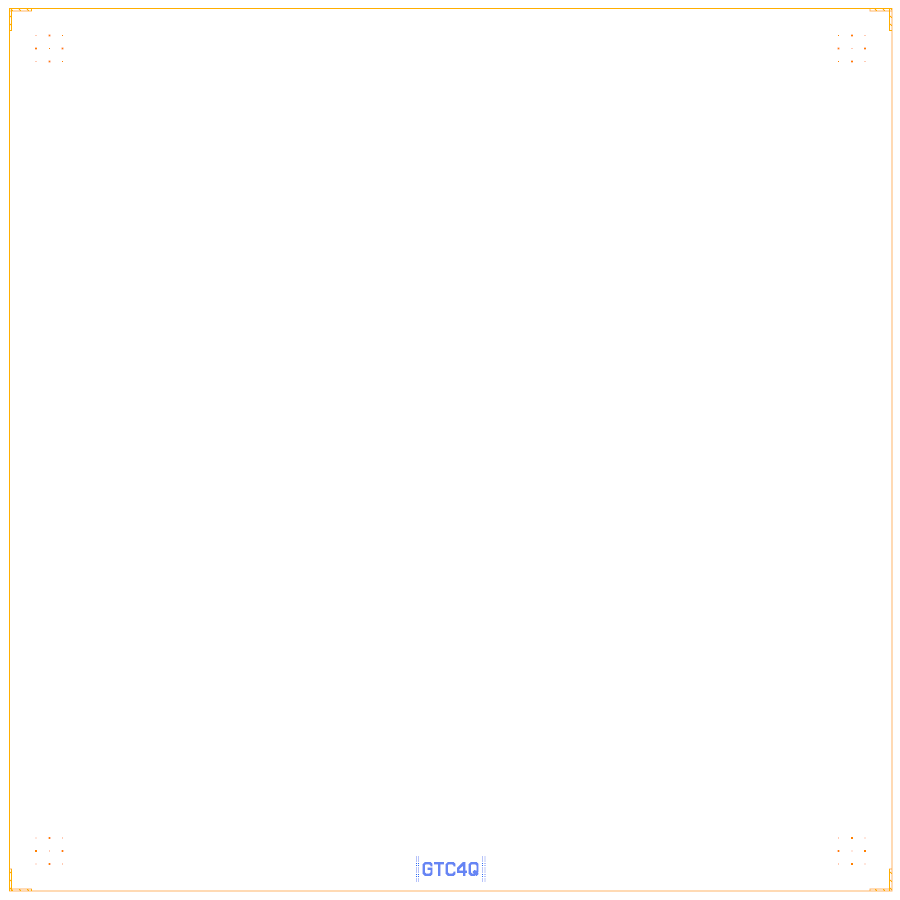

In [4]:
W = H = 10000
X0 = Y0 = 5000
M = lambda sx, sy: (lambda x, y: (X0 - sx * (x - X0), Y0 - sy * (y - Y0)))   # bottom-left quadrant → (sx, sy)
d = Designer("google_tc_2x2", box=(0, 0, W, H), chip={"name_chip": "GTC4Q"}, live=LIVE)
snap(d, OUT / "google_tc_2x2_die.png", size=(900, 900), width=320);

## 3 · Pads: the PDK pad rule

Sixteen `BondPad`s: the two feedlines' four (side edges), an XY and a Z pad per qubit (top and bottom edges), and a Z
pad per coupler (the bottom / top couplers on those edges, the left / right couplers on the side edges, at the
plaquette's height). The PDK puts each pad's outer etch edge **`frame.pad_edge` = 100 µm from the die edge**: `edge="auto"` slides it
perpendicular to its nearest edge until that holds (its position along the edge is kept).

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| FLL_in | `BondPad` | w | 100.0 | ✓ |
| FLL_out | `BondPad` | w | 100.0 | ✓ |
| FLR_in | `BondPad` | e | 100.0 | ✓ |
| FLR_out | `BondPad` | e | 100.0 | ✓ |
| XY_Q00 | `BondPad` | s | 100.0 | ✓ |
| Z_Q00 | `BondPad` | s | 100.0 | ✓ |
| XY_Q10 | `BondPad` | s | 100.0 | ✓ |
| Z_Q10 | `BondPad` | s | 100.0 | ✓ |
| XY_Q01 | `BondPad` | n | 100.0 | ✓ |
| Z_Q01 | `BondPad` | n | 100.0 | ✓ |
| XY_Q11 | `BondPad` | n | 100.0 | ✓ |
| Z_Q11 | `BondPad` | n | 100.0 | ✓ |
| Z_CB | `BondPad` | s | 100.0 | ✓ |
| Z_CT | `BondPad` | n | 100.0 | ✓ |
| Z_CL | `BondPad` | w | 100.0 | ✓ |
| Z_CR | `BondPad` | e | 100.0 | ✓ |

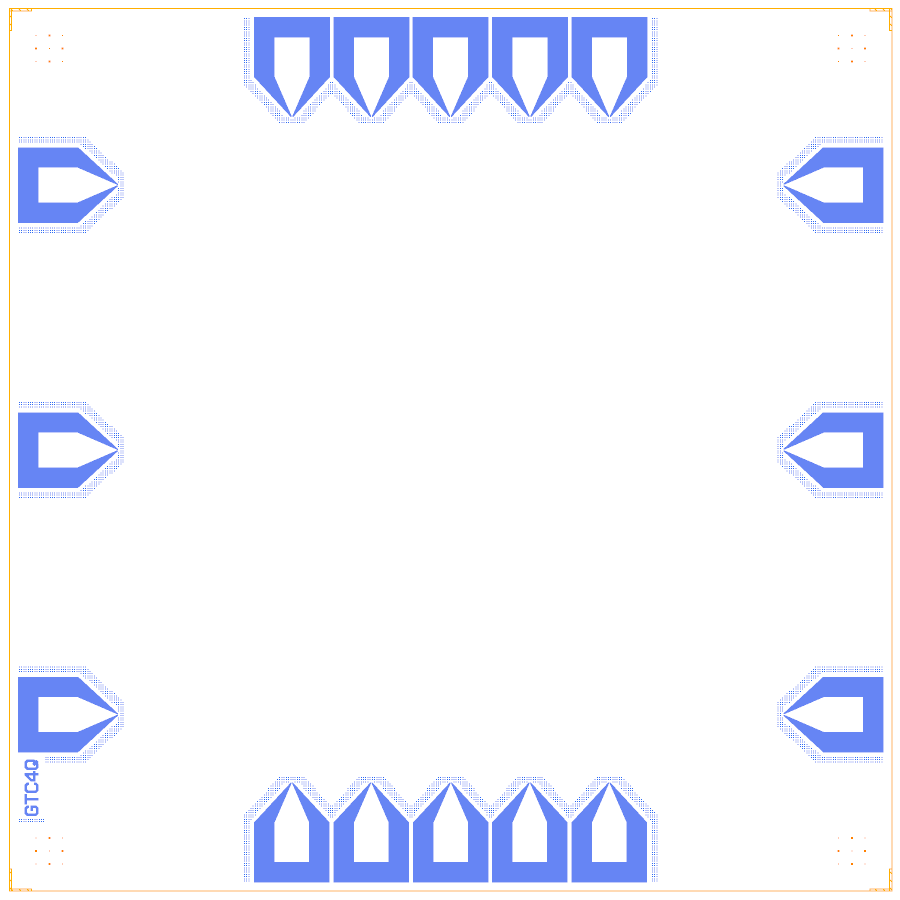

In [5]:
QUBITS = {"Q00": (-1, -1), "Q10": (1, -1), "Q01": (-1, 1), "Q11": (1, 1)}
LQ, WQ, GQ = 160, 30, 30                         # qubit cross (µm)
LC, WC, GC = 70, 20, 20                          # coupler cross
GAP = 100                                        # arm tip ↔ arm tip
S = LQ + GAP + LC                                # qubit ↔ coupler pitch; qubit pitch 2S
# bonds: coupler name → (qubit a, qubit b, centre, rotation: its SQUID arm points out of the plaquette)
BONDS = {"CB": ("Q00", "Q10", (X0, Y0 - S), 0), "CT": ("Q01", "Q11", (X0, Y0 + S), 180),
         "CL": ("Q00", "Q01", (X0 - S, Y0), -90), "CR": ("Q10", "Q11", (X0 + S, Y0), 90)}
pads = {}
pad = lambda n, xy, r: pads.setdefault(n, d.add(n, "BondPad", at=xy, rot=r, edge="auto"))
for side, sx in (("L", -1), ("R", 1)):
    m = M(sx, -1)
    pad(f"FL{side}_in", m(1150, 2000), -90 if sx < 0 else 90)
    pad(f"FL{side}_out", m(1150, 8000), -90 if sx < 0 else 90)
for name, (sx, sy) in QUBITS.items():
    m = M(sx, sy)
    pad(f"XY_{name}", m(3200, 1150), 0 if sy < 0 else 180)
    pad(f"Z_{name}", m(4100, 1150), 0 if sy < 0 else 180)
for name, (qa, qb, (x, y), rot) in BONDS.items():
    if name in ("CB", "CT"):
        pad(f"Z_{name}", (x, 1150 if name == "CB" else H - 1150), 0 if name == "CB" else 180)
    else:
        pad(f"Z_{name}", M(-1 if name == "CL" else 1, -1)(1150, Y0), -90 if name == "CL" else 90)
rebuild(d)
display(Markdown(pads_md(d)))
snap(d, OUT / "google_tc_2x2_pads.png", size=(900, 900), width=320);

## 4 · Components: crosses, trilayer SQUIDs and the couplings

**Junctions.** As in `google_tc_cell`: a Quantcore trilayer SQUID drawn for L_J = 6.1 nH at zero flux in every qubit
and coupler (parallel R_n ≈ 40 kΩ, the low end of the PDK window). The DRC's `pdk_rn` judges the device, the SQUID's two
junctions in parallel (each ≈ 80 kΩ), so these SQUIDs are inside the window and raise no warning.

In [6]:
QJ_PARAMS, QJ = trilayer_junction("metal:TransmonCrossFL", lj_nH=6.1, squid=True)   # R_n ≈ 40 kΩ (PDK window)
CJ_PARAMS, CJ = trilayer_junction("metal:TransmonCrossFL", lj_nH=6.1, squid=True)
print("SQUID (drawn, zero flux):", QJ, f"→ parallel R_n {rn_from_lj(QJ['Lj_nH']) / 1e3:.1f} kΩ")

SQUID (drawn, zero flux): {'Lj_nH': 6.0129, 'Cj_fF': 16.8} → parallel R_n 40.2 kΩ


**Qubits and couplers.** Each qubit's SQUID arm (its local south) points away from the plaquette in y and its readout
claw away in x; each coupler's SQUID arm points out of the plaquette. The claw stops short of the cross's side arms.

In [7]:
CLAW = dict(connector_type="0", claw_length=130, ground_spacing=3, claw_width=30, claw_gap=4)
q, tc = {}, {}
for name, (sx, sy) in QUBITS.items():
    rot = 0 if sy < 0 else 180
    claw_at = {(-1, 0): "0", (1, 0): "180", (-1, 180): "180", (1, 180): "0"}[(sx, rot)]   # Metal: "0" = west
    q[name] = d.add(name, "metal:TransmonCrossFL", at=(X0 + sx * S, Y0 + sy * S), rot=rot, junction=QJ,
                    cross_length=LQ, cross_width=WQ, cross_gap=GQ,
                    connection_pads={"readout": {**CLAW, "connector_location": claw_at}}, **QJ_PARAMS)
for name, (qa, qb, xy, rot) in BONDS.items():
    tc[name] = d.add(name, "metal:TransmonCrossFL", at=xy, rot=rot, junction=CJ, cross_length=LC, cross_width=WC,
                     cross_gap=GC, connection_pads={}, **CJ_PARAMS)
# XY drive ends: an open CPW end at each qubit's outer diagonal
xy_end = {name: d.add(f"XY_{name}_end", "metal:OpenToGround", at=M(sx, sy)(X0 - S - 110, Y0 - S - 170),
                      rot=90 if sy < 0 else -90) for name, (sx, sy) in QUBITS.items()}

**Couplings no route carries** (coplanar-strip estimates, replaced by the `plaquette` Q3D job): qubit ↔ coupler on
every bond, the direct qubit ↔ qubit capacitance across every coupler (screened), and the two diagonals across the
plaquette.

C(Q ↔ C) ≈ 2.35 fF, C(Q ↔ Q, bond) ≈ 0.282 fF, C(Q ↔ Q, diagonal) ≈ 0.08 fF


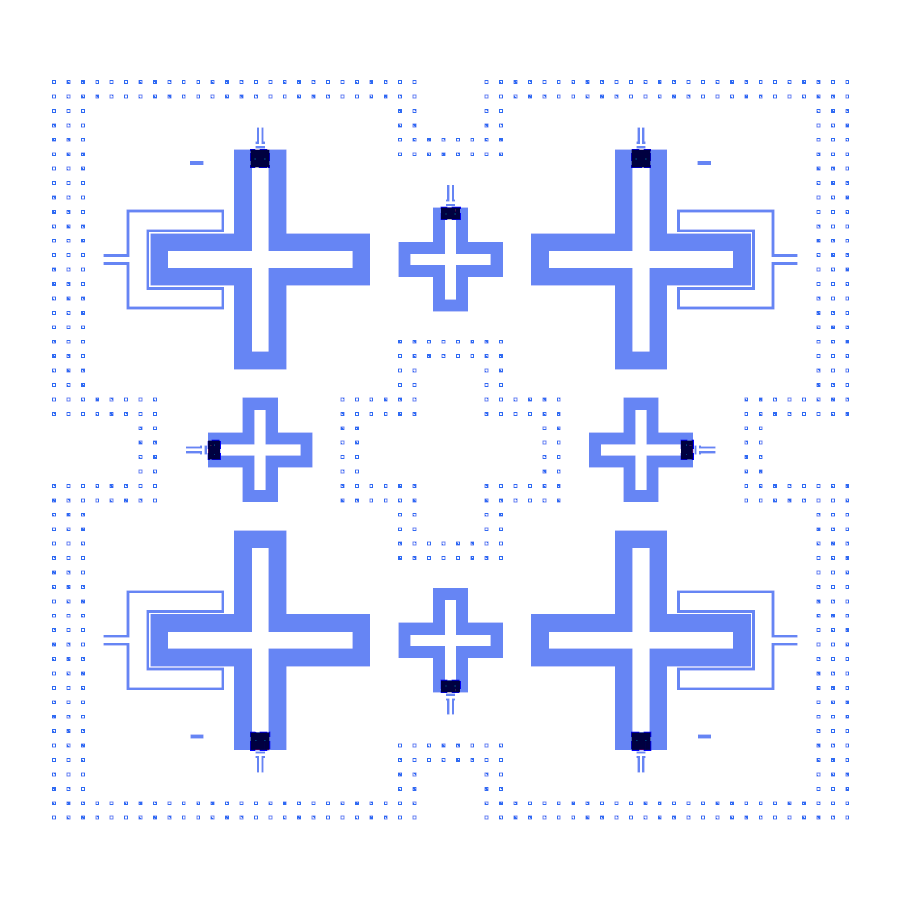

In [8]:
C_QC = round(est.coplanar_coupling(WQ, LQ, LC, GAP, EPS), 2)
C_QQ = round(est.coplanar_coupling(WQ, LQ, LQ, 2 * GAP + 2 * LC, EPS, screening=0.15), 3)
C_DIAG = round(est.coplanar_coupling(WQ, LQ, LQ, 2 * math.sqrt(2) * S - 2 * LQ, EPS, screening=0.05), 3)
print(f"C(Q ↔ C) ≈ {C_QC} fF, C(Q ↔ Q, bond) ≈ {C_QQ} fF, C(Q ↔ Q, diagonal) ≈ {C_DIAG} fF")
for name, (qa, qb, _, _) in BONDS.items():
    d.couple(f"Cg_{qa}_{name}", qa, name, C_fF=C_QC, note="qubit arm tip ↔ coupler arm tip, 100 µm (CPS)")
    d.couple(f"Cg_{name}_{qb}", name, qb, C_fF=C_QC, note="coupler arm tip ↔ qubit arm tip, 100 µm (CPS)")
    d.couple(f"Cg_{qa}_{qb}", qa, qb, C_fF=C_QQ, note="qubit ↔ qubit across the coupler (CPS, screening 0.15)")
d.couple("Cg_Q00_Q11", "Q00", "Q11", C_fF=C_DIAG, note="diagonal, across the plaquette (CPS, screening 0.05)")
d.couple("Cg_Q10_Q01", "Q10", "Q01", C_fF=C_DIAG, note="diagonal, across the plaquette (CPS, screening 0.05)")
snap(d, OUT / "google_tc_2x2_components.png", box=(X0 - S - 450, Y0 - S - 450, X0 + S + 450, Y0 + S + 450),
     size=(900, 900), width=360);

## 5 · Routes: feedlines, readouts, XY and Z lines

- **Feedlines:** left (Q00, Q01) and right (Q10, Q11), vertical at x = `XF` / W − `XF`, between their side pads.
- **Readouts:** λ/4 from each claw, out in x then along a vertical run (the meander) into a 900 µm **hanger** on its
  feedline, shorted at its end; `fl.hanger(near=(x, y))` centres the coupler at the feedline point nearest (x, y)
  (`Y_HANG` on the vertical run): given by position, not by arclength from the pad, it stays put when the pads (and so
  the feedline's start) move, and each readout's last leg meets its coupler square.
- **XY lines:** from the XY pad round the outside of the plaquette to the open end at the qubit's outer diagonal.
- **Z lines:** each qubit's flux T-line to its pad; the bottom / top couplers straight down / up; the left / right
  couplers' lines cross the feedline on an **airbridge** (`d.waypoint(..., airbridge=True)`).

In [9]:
XF = 2700                                        # left feedline (the right one at W − XF)
K_LEN = 900                                      # hanger coupling length
Y_HANG = {"Q00": 3300, "Q01": 6700, "Q10": 3300, "Q11": 6700}       # hanger centres on the vertical feedlines
fl = {}
for side, sx in (("L", -1), ("R", 1)):
    m = M(sx, -1)
    fl[side] = d.route(f"FL{side}", pads[f"FL{side}_in"].a, pads[f"FL{side}_out"].a, r=100,
                       nodes=[m(XF, 2000), m(XF, 8000)])
for name, (sx, sy) in QUBITS.items():
    m = M(sx, sy)
    side = "L" if sx < 0 else "R"
    yh = Y_HANG[name]
    y_start = yh - K_LEN / 2 if sy < 0 else yh + K_LEN / 2          # the coupler starts on the lattice side
    hang = fl[side].hanger(near=(XF if sx < 0 else W - XF, yh), length=K_LEN, side="right" if sx < 0 else "left", ground_gap=4, end="short",
                           direction="forward" if sy < 0 else "backward")
    xr = m(3500, Y0)[0]                                              # the readout's vertical run (meander)
    d.route(f"R_{name}", q[name].readout, hang, meander=L_READ[name], r=50, nodes=[(xr, Y0 + sy * S), (xr, y_start)])
    d.route(f"XY_{name}_line", pads[f"XY_{name}"].a, xy_end[name].open, r=50,
            nodes=[m(3200, 1800), m(4000, 1800), m(4000, Y0 - S - 300), m(X0 - S - 110, Y0 - S - 300)])
    d.route(f"Z_{name}_line", q[name].flux_line, pads[f"Z_{name}"].a, r=50, nodes=[m(X0 - S, 2000), m(4100, 2000)])
for name, (qa, qb, (x, y), rot) in BONDS.items():
    if name in ("CB", "CT"):
        d.route(f"Z_{name}_line", tc[name].flux_line, pads[f"Z_{name}"].a, r=50)
    else:
        sx = -1 if name == "CL" else 1
        d.route(f"Z_{name}_line", tc[name].flux_line, pads[f"Z_{name}"].a, r=50,
                nodes=[d.waypoint(M(sx, -1)(XF, Y0), airbridge=True)])
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

{'FLL': 8864.2, 'FLR': 8864.2, 'R_Q00': 6243.0, 'XY_Q00_line': 4549.2, 'Z_Q00_line': 3743.6, 'R_Q10': 6122.0, 'XY_Q10_line': 4549.2, 'Z_Q10_line': 3743.6, 'R_Q01': 6182.0, 'XY_Q01_line': 4549.2, 'Z_Q01_line': 3743.6, 'R_Q11': 6064.0, 'XY_Q11_line': 4549.2, 'Z_Q11_line': 3743.6, 'Z_CB_line': 3316.5, 'Z_CT_line': 3316.5, 'Z_CL_line': 3316.5, 'Z_CR_line': 3316.5}


## 6 · PDK placement, targets and FEM groups

`center_in_die(d)` measures the bounding box of all instances and routes and shifts them to centre it in the die; here
the plaquette was laid out round the die centre, so it returns (0, 0) (no shift within its 50 µm tolerance).

The targets are the source's; two sim groups define the FEM boxes: the `plaquette` (4 qubits, 4 couplers, the XY ends:
the C-matrix replaces every `d.couple` estimate) and `Q00_read` (Q00 with its readout). The layout is complete and is
saved.

In [10]:
print("centring shift (µm):", center_in_die(d))
d.targets(**{n: {"f_q_GHz": SRC["f_q_idle_GHz"], "alpha_MHz": SRC["alpha_MHz"]} for n in QUBITS},
          **{f"R_{n}": {"f_GHz": F_R[n], "kappa_MHz": SRC["kappa_MHz"]} for n in QUBITS})
d.sim_group("plaquette", list(QUBITS) + list(BONDS) + [f"XY_{n}_end" for n in QUBITS], margin_um=60,
            analyses=["q3d_cmatrix"])
d.sim_group("Q00_read", ["Q00", "R_Q00"], margin_um=60, analyses=["q3d_cmatrix", "eigenmode_epr"])
DESIGN = d.save(OUT / "google_tc_2x2.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)
<Designer google_tc_2x2: 28 instances, 18 routes, live=False> → examples\designs\google\google_tc_2x2.json


## 7 · DRC

- **errors:** none expected;
- **warnings:** `dangling_port` on the `squid_a` / `squid_b` junction attachment points of the eight crosses (the cell
  draws the trilayer SQUID itself), and four `overlap`s: each XY end sits inside its qubit's bounding box, at the outer
  diagonal of the cross, by design (zoom in step 14);
- **PDK design warnings:** none expected (every SQUID's parallel R_n ≈ 40 kΩ is in the window, step 4; the f_q
  targets are in 4–8 GHz; every pad at 100 µm).

This run: **0 errors · 20 warnings (16 `dangling_port`, 4 `overlap`) · 0 PDK design warnings**; the drawn SQUID is
6.01 nH, parallel R_n 40.2 kΩ.

In [11]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 20 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 16 | CB.squid_a is not connected (no route or snap) |
| warning | `overlap` | 4 | Q00 and XY_Q00_end overlap |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 8 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

Eight grounded islands with SQUIDs (4 qubits, 4 couplers), a claw node per qubit with its λ/4 readout `TLres` and
hanger κ into `FLL` / `FLR`, XY ends as 50 Ω drive ports, the Z lines as `flux_bias` controls; the `d.couple`
capacitances (qubit–coupler on every bond, the direct qubit–qubit capacitance across every coupler and the two
diagonals). The airbridges join the two halves of each side coupler's Z line (one conductor).

In [12]:
lb = d.lom()
show_netlist(lb)

**19 nodes · 54 branches · 8 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FLL` | `FLL`, `FLL_in.pad`, `FLL_out.pad` |
| `FLR` | `FLR`, `FLR_in.pad`, `FLR_out.pad` |
| `XY_Q00_end.end` | `XY_Q00.pad`, `XY_Q00_end.end` |
| `XY_Q10_end.end` | `XY_Q10.pad`, `XY_Q10_end.end` |
| `XY_Q01_end.end` | `XY_Q01.pad`, `XY_Q01_end.end` |
| `XY_Q11_end.end` | `XY_Q11.pad`, `XY_Q11_end.end` |
| `Q00` | `Q00.island` |
| `Q00.readout` | `Q00.readout` |
| `Q10` | `Q10.island` |
| `Q10.readout` | `Q10.readout` |
| `Q01` | `Q01.island` |
| `Q01.readout` | `Q01.readout` |
| `Q11` | `Q11.island` |
| `Q11.readout` | `Q11.readout` |
| `CB` | `CB.island` |
| `CT` | `CT.island` |
| `CL` | `CL.island` |
| `CR` | `CR.island` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_FLL_in` | R | `FLL` – `gnd` | 50 Ω |
| `Port_FLL_out` | R | `FLL` – `gnd` | 50 Ω |
| `Port_FLR_in` | R | `FLR` – `gnd` | 50 Ω |
| `Port_FLR_out` | R | `FLR` – `gnd` | 50 Ω |
| `Port_XY_Q00` | R | `XY_Q00_end.end` – `gnd` | 50 Ω |
| `Port_XY_Q10` | R | `XY_Q10_end.end` – `gnd` | 50 Ω |
| `Port_XY_Q01` | R | `XY_Q01_end.end` – `gnd` | 50 Ω |
| `Port_XY_Q11` | R | `XY_Q11_end.end` – `gnd` | 50 Ω |
| `C_Q00` | C | `Q00` – `gnd` | 67.9 fF |
| `J_Q00` | SQUID | `Q00` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `Cg_Q00_readout` | C | `Q00` – `Q00.readout` | 4 fF |
| `Cc_Q00_readout` | C | `Q00.readout` – `gnd` | 104 fF |
| `C_Q10` | C | `Q10` – `gnd` | 67.9 fF |
| `J_Q10` | SQUID | `Q10` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `Cg_Q10_readout` | C | `Q10` – `Q10.readout` | 4 fF |
| `Cc_Q10_readout` | C | `Q10.readout` – `gnd` | 104 fF |
| `C_Q01` | C | `Q01` – `gnd` | 67.9 fF |
| `J_Q01` | SQUID | `Q01` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `Cg_Q01_readout` | C | `Q01` – `Q01.readout` | 4 fF |
| `Cc_Q01_readout` | C | `Q01.readout` – `gnd` | 104 fF |
| `C_Q11` | C | `Q11` – `gnd` | 67.9 fF |
| `J_Q11` | SQUID | `Q11` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `Cg_Q11_readout` | C | `Q11` – `Q11.readout` | 4 fF |
| `Cc_Q11_readout` | C | `Q11.readout` – `gnd` | 104 fF |
| `C_CB` | C | `CB` – `gnd` | 29 fF |
| `J_CB` | SQUID | `CB` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `C_CT` | C | `CT` – `gnd` | 29 fF |
| `J_CT` | SQUID | `CT` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `C_CL` | C | `CL` – `gnd` | 29 fF |
| `J_CL` | SQUID | `CL` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `C_CR` | C | `CR` – `gnd` | 29 fF |
| `J_CR` | SQUID | `CR` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `C_Cg_Q00_CB` | C | `Q00` – `CB` | 2.35 fF |
| `C_Cg_CB_Q10` | C | `CB` – `Q10` | 2.35 fF |
| `C_Cg_Q00_Q10` | C | `Q00` – `Q10` | 0.282 fF |
| `C_Cg_Q01_CT` | C | `Q01` – `CT` | 2.35 fF |
| `C_Cg_CT_Q11` | C | `CT` – `Q11` | 2.35 fF |
| `C_Cg_Q01_Q11` | C | `Q01` – `Q11` | 0.282 fF |
| `C_Cg_Q00_CL` | C | `Q00` – `CL` | 2.35 fF |
| `C_Cg_CL_Q01` | C | `CL` – `Q01` | 2.35 fF |
| `C_Cg_Q00_Q01` | C | `Q00` – `Q01` | 0.282 fF |
| `C_Cg_Q10_CR` | C | `Q10` – `CR` | 2.35 fF |
| `C_Cg_CR_Q11` | C | `CR` – `Q11` | 2.35 fF |
| `C_Cg_Q10_Q11` | C | `Q10` – `Q11` | 0.282 fF |
| `C_Cg_Q00_Q11` | C | `Q00` – `Q11` | 0.08 fF |
| `C_Cg_Q10_Q01` | C | `Q10` – `Q01` | 0.08 fF |
| `R_Q00` | TLres | `Q00.readout` – `gnd` | lambda/4, 6243 µm, 5.047 GHz |
| `K_R_Q00` | HANGER | `Q00.readout` – `FLL` | κ 1.06 MHz (L 900 µm) |
| `R_Q10` | TLres | `Q10.readout` – `gnd` | lambda/4, 6122 µm, 5.147 GHz |
| `K_R_Q10` | HANGER | `Q10.readout` – `FLR` | κ 1.13 MHz (L 900 µm) |
| `R_Q01` | TLres | `Q01.readout` – `gnd` | lambda/4, 6182 µm, 5.097 GHz |
| `K_R_Q01` | HANGER | `Q01.readout` – `FLL` | κ 1.09 MHz (L 900 µm) |
| `R_Q11` | TLres | `Q11.readout` – `gnd` | lambda/4, 6064 µm, 5.196 GHz |
| `K_R_Q11` | HANGER | `Q11.readout` – `FLR` | κ 1.16 MHz (L 900 µm) |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `Z_Q00_line` | flux_bias | `J_Q00` | `Z_Q00_line` | 3744 |
| `Z_Q10_line` | flux_bias | `J_Q10` | `Z_Q10_line` | 3744 |
| `Z_Q01_line` | flux_bias | `J_Q01` | `Z_Q01_line` | 3744 |
| `Z_Q11_line` | flux_bias | `J_Q11` | `Z_Q11_line` | 3744 |
| `Z_CB_line` | flux_bias | `J_CB` | `Z_CB_line` | 3316 |
| `Z_CT_line` | flux_bias | `J_CT` | `Z_CT_line` | 3316 |
| `Z_CL_line` | flux_bias | `J_CL` | `Z_CL_line` | 3316 |
| `Z_CR_line` | flux_bias | `J_CR` | `Z_CR_line` | 3316 |

**Unconnected ports:** none

**Builder notes:**

- Port_Z_Q00: both ends on gnd after merging conductors (dropped)
- Port_Z_Q10: both ends on gnd after merging conductors (dropped)
- Port_Z_Q01: both ends on gnd after merging conductors (dropped)
- Port_Z_Q11: both ends on gnd after merging conductors (dropped)
- Port_Z_CB: both ends on gnd after merging conductors (dropped)
- Port_Z_CT: both ends on gnd after merging conductors (dropped)
- Port_Z_CL: both ends on gnd after merging conductors (dropped)
- Port_Z_CR: both ends on gnd after merging conductors (dropped)

## 9 · LOM simulation

**(a) Qubit + readout pairs** (QuTiP dressed; targets in brackets; the couplers are outside these groups).
The λ/4 lengths were calibrated before the Nb film's kinetic inductance (PDK `kinetic`) entered the LOM;
with it every line is ≈ 1.6 % slower, so f_r lands ≈ 75 MHz below its target. Flagged, not retuned (values are not
the point of the rebuild). This run: f_q 6.6675 GHz (all four), α −236.5 MHz; f_r 4.4873 / 4.5269 /
4.5665 / 4.6055 GHz (Q00, Q01, Q10, Q11); κ 0.66–0.71 MHz; χ −0.17 … −0.21 MHz.

In [13]:
read = {f"{n}+R": [n, f"R_{n}", "FLL" if n in ("Q00", "Q01") else "FLR"] for n in QUBITS}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, d.data["targets"])))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q00+R | Q00 | 6.6675 (6.661) | -236.5 (-208) | R_Q00 | 4.4873 (4.56) | 0.663 (0.64) | -0.172 |
| Q10+R | Q10 | 6.6676 (6.661) | -236.5 (-208) | R_Q10 | 4.5665 (4.64) | 0.697 (0.64) | -0.196 |
| Q01+R | Q01 | 6.6675 (6.661) | -236.5 (-208) | R_Q01 | 4.5269 (4.6) | 0.68 (0.64) | -0.184 |
| Q11+R | Q11 | 6.6676 (6.661) | -236.5 (-208) | R_Q11 | 4.6055 (4.68) | 0.714 (0.64) | -0.21 |

**(b) Coupler sweep on the bottom bond (Q00–CB–Q10)**; the four bonds are the same geometry. As in `google_tc_cell`:
degenerate qubits → 2|g̃| from the dressed splitting, sign from Yan's Eq. 5; Q10 detuned by `DETUNE_LJ` for the
static ZZ. This run gives the cell's numbers: g̃ +5.0 MHz at f_c,max (8.765 GHz), 0 at f_c ≈ 7.772 GHz
(L_J,c 7.56 nH, Φ ≈ 0.208 Φ0), −25.9 MHz at 6.943 GHz.

| L_J,c (nH) | Φ/Φ0 | f_c (GHz) | α_c (MHz) | f_q1 (GHz) | f_q2 (GHz) | 2·abs(g̃) (MHz) | g̃ (MHz) | g̃ Yan Eq. 5 (MHz) | ZZ (kHz), q2 detuned |
|---|---|---|---|---|---|---|---|---|---|
| 6.00 | 0.000 | 8.7653 | -423.9 | 6.5671 | 6.5771 | 10 | 5.01 | 5.1 | -199.8 |
| 6.50 | 0.126 | 8.4077 | -423.3 | 6.5671 | 6.5748 | 7.7 | 3.85 | 3.98 | -154.6 |
| 7.00 | 0.172 | 8.0900 | -420.8 | 6.5671 | 6.5718 | 4.7 | 2.35 | 2.53 | -113.5 |
| 7.25 | 0.190 | 7.9441 | -418.2 | 6.5671 | 6.5699 | 2.84 | 1.42 | 1.64 | -97.93 |
| 7.50 | 0.205 | 7.8059 | -414.3 | 6.5671 | 6.5678 | 0.664 | 0.332 | 0.614 | -89.11 |
| 7.75 | 0.218 | 7.6750 | -408.5 | 6.5671 | 6.5652 | 1.91 | -0.955 | -0.596 | -91.98 |
| 8.00 | 0.230 | 7.5509 | -399.7 | 6.5621 | 6.5671 | 5 | -2.5 | -2.03 | -115 |
| 8.50 | 0.251 | 7.3219 | -367.1 | 6.5536 | 6.5671 | 13.5 | -6.73 | -5.87 | -295.8 |
| 9.00 | 0.268 | 7.1183 | -301.9 | 6.5399 | 6.5671 | 27.2 | -13.6 | -11.7 | -1029 |
| 9.25 | 0.275 | 7.0266 | -256.4 | 6.5296 | 6.5671 | 37.5 | -18.8 | -15.8 | -2057 |
| 9.50 | 0.282 | 6.9427 | -206.9 | 6.5154 | 6.5671 | 51.7 | -25.9 | -20.9 | -4397 |

**Off point:** f_c ≈ 7.772 GHz (L_J,c ≈ 7.56 nH, Φ ≈ 0.208 Φ0)

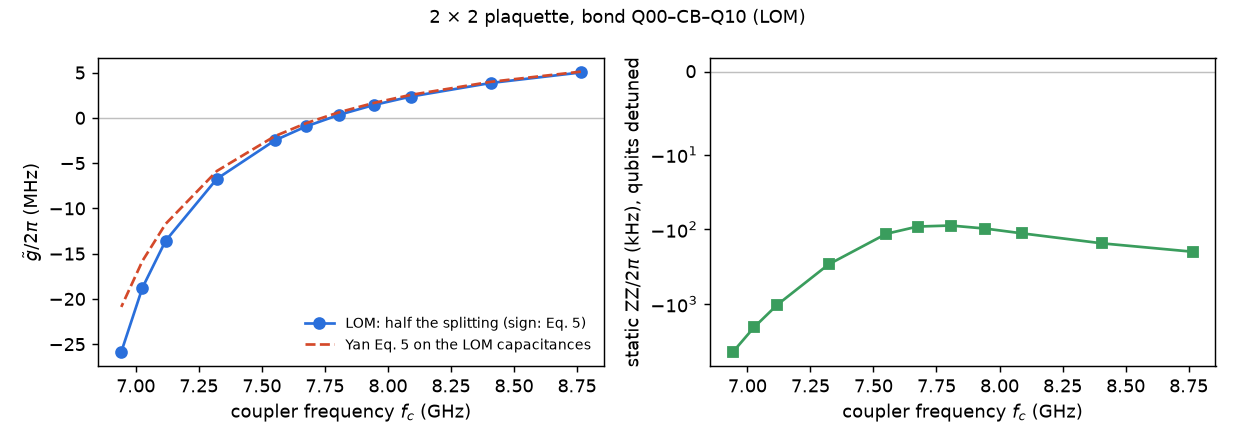

WindowsPath('examples/designs/google/google_tc_2x2_sweep.png')

In [14]:
LJ_C = [6.0, 6.5, 7.0, 7.25, 7.5, 7.75, 8.0, 8.5, 9.0, 9.25, 9.5]
DETUNE_LJ = 6.9
sweep = coupler_sweep(d, ["Q00", "CB", "Q10"], "Q00", "Q10", "CB", LJ_C, detune_lj=DETUNE_LJ)
display(Markdown(coupler_sweep_md(sweep)))
off = off_point(sweep)
display(Markdown(f"**Off point:** f_c ≈ {off['f_c_GHz']:.3f} GHz (L_J,c ≈ {off['lj_nH']:.2f} nH, Φ ≈ "
                 f"{off['flux_phi0']:.3f} Φ0)" if off else "**Off point:** not inside the sweep"))
plot_coupler_sweep(sweep, OUT / "google_tc_2x2_sweep.png", title="2 × 2 plaquette, bond Q00–CB–Q10 (LOM)")

**(c) The plaquette at idle, bond by bond**: every coupler at the off point, the qubits in a checkerboard (Q00 / Q11
at the design L_J, Q10 / Q01 at `DETUNE_LJ`), each bond (qubit – coupler – qubit) simulated with QuTiP: dressed
frequencies and the residual static ZZ of each neighbouring pair. (All eight junctions in one QuCat network exceed
its symbolic solver, so the plaquette is taken bond by bond; the two diagonals couple only through the 0.08 fF
estimate.) The junction values change in the LOM only and are put back afterwards.

This run: on every bond the qubits sit at 6.567 (Q00, Q11) and 6.119 GHz (Q10, Q01) and the coupler at 7.767 GHz;
the residual static ZZ of each neighbouring qubit pair is −88 kHz.

In [15]:
lj_off = round(off["lj_nH"], 4) if off else LJ_C[0]
for n in BONDS:
    d[n].spec["junction"] = {**CJ, "Lj_nH": lj_off}             # couplers at the off point (LOM only)
for n in ("Q10", "Q01"):
    d[n].spec["junction"] = {**QJ, "Lj_nH": DETUNE_LJ}          # checkerboard detuning (LOM only)
idle = simulate_groups(d, {f"{qa}–{name}–{qb}": [qa, name, qb] for name, (qa, qb, _, _) in BONDS.items()},
                       max_modes=3)
for n in BONDS:
    d[n].spec["junction"] = dict(CJ)
for n in ("Q10", "Q01"):
    d[n].spec["junction"] = dict(QJ)
display(Markdown(groups_md(idle)))
display(Markdown(zz_md(idle)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q00–CB–Q10 | Q10 | 6.1186 | -228.9 | – | – | – | – |
|  | Q00 | 6.5671 | -225.2 | – | – | – | – |
|  | CB | 7.7673 | -419.9 | – | – | – | – |
| Q01–CT–Q11 | Q01 | 6.1186 | -228.9 | – | – | – | – |
|  | Q11 | 6.5671 | -225.2 | – | – | – | – |
|  | CT | 7.7673 | -419.9 | – | – | – | – |
| Q00–CL–Q01 | Q01 | 6.1186 | -228.9 | – | – | – | – |
|  | Q00 | 6.5671 | -225.2 | – | – | – | – |
|  | CL | 7.7673 | -419.9 | – | – | – | – |
| Q10–CR–Q11 | Q10 | 6.1186 | -228.9 | – | – | – | – |
|  | Q11 | 6.5671 | -225.2 | – | – | – | – |
|  | CR | 7.7673 | -419.9 | – | – | – | – |

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q00–CB–Q10 | Q00-Q10 | -88.47 | yes | no |
| Q00–CB–Q10 | CB-Q10 | -7609 | yes | no |
| Q00–CB–Q10 | CB-Q00 | -1.695e+04 | yes | no |
| Q01–CT–Q11 | Q01-Q11 | -88.47 | yes | no |
| Q01–CT–Q11 | CT-Q01 | -7609 | yes | no |
| Q01–CT–Q11 | CT-Q11 | -1.695e+04 | yes | no |
| Q00–CL–Q01 | Q00-Q01 | -88.47 | yes | no |
| Q00–CL–Q01 | CL-Q01 | -7609 | yes | no |
| Q00–CL–Q01 | CL-Q00 | -1.695e+04 | yes | no |
| Q10–CR–Q11 | Q10-Q11 | -88.47 | yes | no |
| Q10–CR–Q11 | CR-Q10 | -7609 | yes | no |
| Q10–CR–Q11 | CR-Q11 | -1.695e+04 | yes | no |

## 10 · FEM: send the job

Three jobs: a Q3D C-matrix job for the `plaquette` (4 qubits, 4 couplers, the XY ends) and, for `Q00_read`, a
C-matrix and an eigenmode job with its readout. Simulation exports draw the junctions as lumped lines and never carry
cheese; airbridges are left out unless `build_simulation(..., airbridges=True)`. Exporting again replaces a job folder,
results included.

`RUN_FEM = False` only exports. With `RUN_FEM = True` and AEDT 2024 R1 (or newer) here, `send_fem_jobs` solves each job in
a **new batch, non-graphical AEDT** (`solve_job`); an open AEDT window is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [16]:
RUN_FEM = False                                  # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
jobs = export_sims(DESIGN, ["plaquette", "Q00_read"])
jobs_eig = export_sims(DESIGN, ["Q00_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    send_fem_jobs(DESIGN, ["plaquette", "Q00_read"], run=True)   # each group's own analyses

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| plaquette | `build/jobs/google_tc_2x2_plaquette_q3d_cmatrix` | 1 · junction · `Q00.junction`<br>2 · junction · `Q10.junction`<br>3 · junction · `Q01.junction`<br>4 · junction · `Q11.junction`<br>5 · junction · `CB.junction`<br>6 · junction · `CT.junction`<br>7 · junction · `CL.junction`<br>8 · junction · `CR.junction`<br>9 · edge · `XY_Q00_line`<br>10 · edge · `XY_Q01_line`<br>11 · edge · `XY_Q10_line`<br>12 · edge · `XY_Q11_line`<br>13 · edge · `Z_CB_line`<br>14 · edge · `Z_CL_line`<br>15 · edge · `Z_CR_line`<br>16 · edge · `Z_CT_line`<br>17 · edge · `Z_Q00_line`<br>18 · edge · `Z_Q01_line`<br>19 · edge · `Z_Q10_line`<br>20 · edge · `Z_Q11_line` | `Q00.island`, `Q10.island`, `Q01.island`, `Q11.island`, `CB.island`, `CT.island`, `CL.island`, `CR.island`, `XY_Q00_line`, `XY_Q01_line`, `XY_Q10_line`, `XY_Q11_line` |
| Q00_read | `build/jobs/google_tc_2x2_Q00_read_q3d_cmatrix` | 1 · junction · `Q00.junction`<br>2 · waveguide · `Q00.readout`<br>3 · edge · `XY_Q00_line`<br>4 · edge · `Z_Q00_line` | `Q00.island`, `XY_Q00_line` |
| Q00_read | `build/jobs/google_tc_2x2_Q00_read_eigenmode_epr` | 1 · junction · `Q00.junction`<br>2 · edge_lumped · `FLL`<br>3 · edge_lumped · `FLL`<br>4 · edge_lumped · `XY_Q00_line`<br>5 · edge_lumped · `Z_Q00_line` | `Q00.island`, `FLL`, `FLL#2`, `XY_Q00_line`, `Z_Q00_line` |

## 11 · Bring the results back

With results in `build/jobs/<job>/results/results.json`, `fill(model, design, job)` replaces the LOM capacitance
estimates by net name: the plaquette C-matrix over the eight islands and four XY lines replaces every `d.couple`
value; steps 9 (b)–(c) can then be run again on them. Until a solve has run, the cell says what would appear.

In [17]:
filled, md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                         **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(md))

No FEM results yet for plaquette · q3d, Q00_read · q3d, Q00_read · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Iterate: change one property and re-simulate

The bottom coupler's arms go from 70 to 60 µm: a smaller cross has less capacitance, so its maximum frequency (and
|α_c|) rises and its pull on the qubits changes. The bond Q00–CB–Q10 is simulated with the coupler at zero flux and
Q10 detuned (`DETUNE_LJ`, as in 9 c: degenerate qubits would hybridise), before and after. `design_copy` opens a
second, non-live Designer on the saved design; the design file stays as it is. This run: CB's f_c,max 8.754 → 9.151 GHz
and α_c −425 → −471 MHz; the qubits move by less than 1 MHz (Q00 6.5722 → 6.5727, Q10 6.1211 → 6.1213 GHz).

In [18]:
bond = {"Q00–CB–Q10": ["Q00", "CB", "Q10"]}
d2 = design_copy(DESIGN)
d2["Q10"].spec["junction"] = {**QJ, "Lj_nH": DETUNE_LJ}      # detuned pair (LOM only)
before = simulate_groups(d2, bond, max_modes=3)
d2["CB"].set(cross_length=60)
after = simulate_groups(d2, bond, max_modes=3)
display(Markdown(params_delta_md(before, after)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q00–CB–Q10: Q10.f_q_GHz` | 6.1211 | 6.1213 | +0.0002395 |
| `Q00–CB–Q10: Q10.alpha_MHz` | -230.17 | -230.31 | -0.1348 |
| `Q00–CB–Q10: Q00.f_q_GHz` | 6.5722 | 6.5727 | +0.0004953 |
| `Q00–CB–Q10: Q00.alpha_MHz` | -227.96 | -228.23 | -0.2691 |
| `Q00–CB–Q10: CB.f_q_GHz` | 8.7537 | 9.1505 | +0.3969 |
| `Q00–CB–Q10: CB.alpha_MHz` | -425.15 | -470.92 | -45.77 |

## 13 · Build and export

- **Design file:** `examples/designs/google/google_tc_2x2.json` (step 6); `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (the PDK band: no original cheese exists; this run: 22 733 holes); the airbridges go to 300/0 + 301/0.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps the airbridges
  in a FEM export; cheese never.
- **The same from the command line:** `qcc build examples/designs/google/google_tc_2x2.json`, `qcc design drc …`,
  `qcc mask …`, `qcc sim build … -g plaquette -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [19]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 22774 |
| 2/0 | JJ_STRAIGHT | 8 |
| 3/0 | M3 | 22739 |
| 4/0 | JJ_BENT | 8 |
| 50/0 | HSQ | 32 |
| 51/0 | SPACER_1 | 32 |
| 52/0 | SPACER_2 | 32 |
| 53/0 | SPACER_3 | 32 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 300/0 | AIRBRIDGE_PADS | 12 |
| 301/0 | AIRBRIDGE_BRIDGE | 6 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 22733 holes on the mask.

→ `build/google_tc_2x2_fab.oas`

## 14 · Snapshots

The full die (16 pads, two vertical feedlines, four λ/4 meanders, the plaquette in the centre, QCT device ID); the
plaquette (four crosses and four small couplers, every SQUID arm pointing outwards, the claws and XY ends); a coupler's
SQUID; the left coupler's Z line crossing the left feedline on its airbridge; and the fab mask round the plaquette (the
PDK band's 5 µm holes along the 3/0 keep-outs, on 1/0 and 3/0, the junction layers).

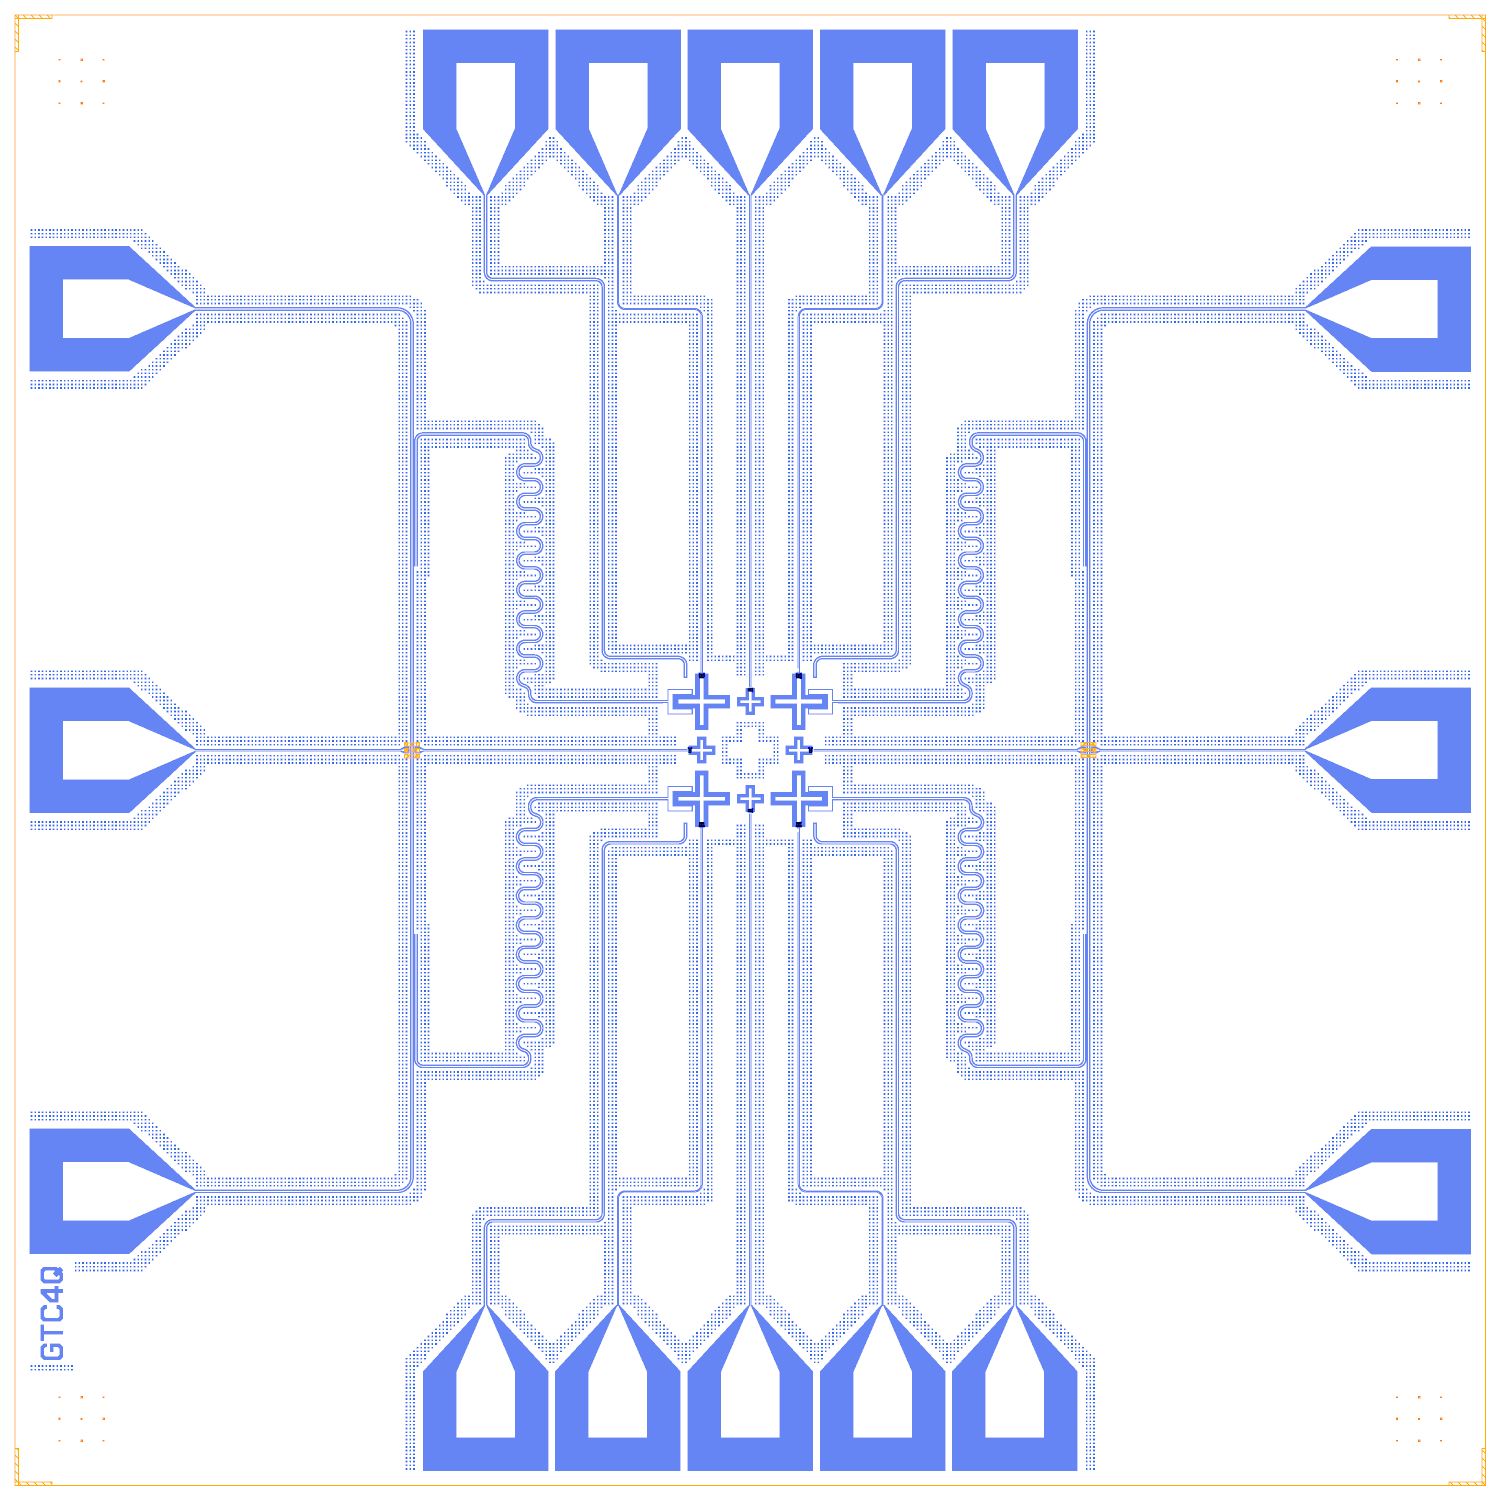

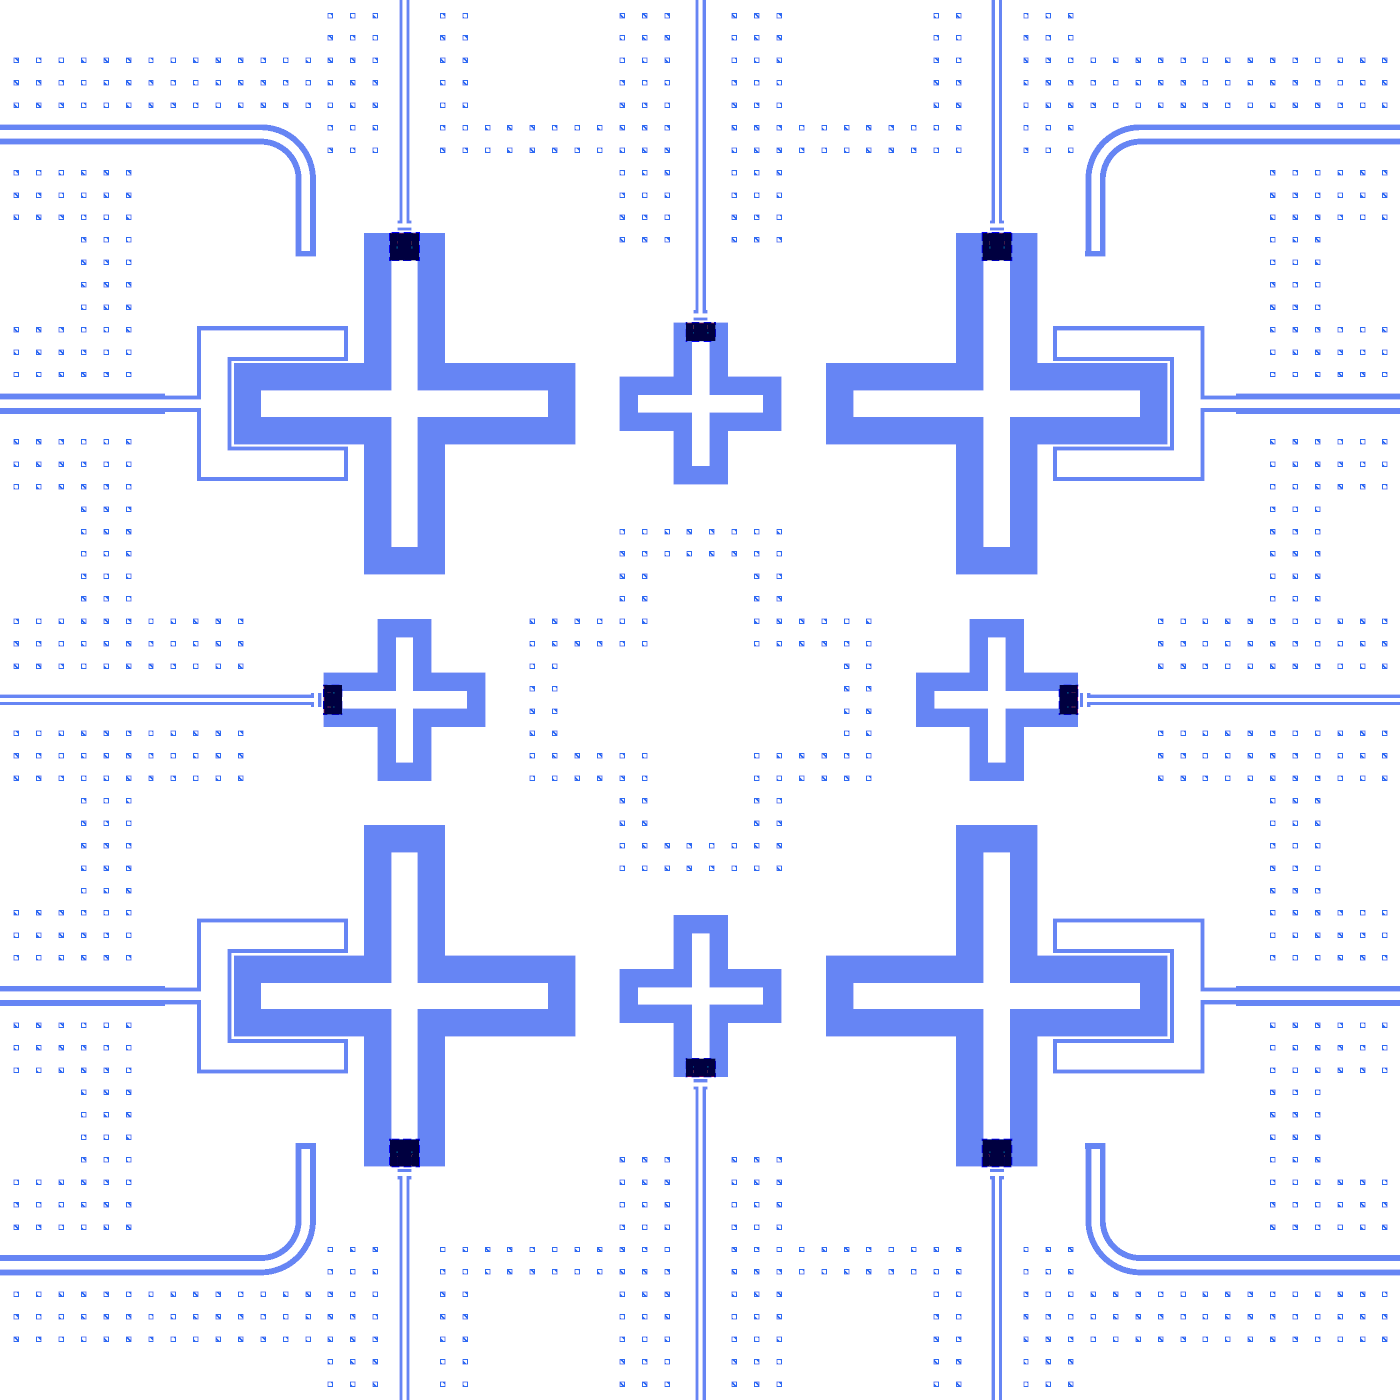

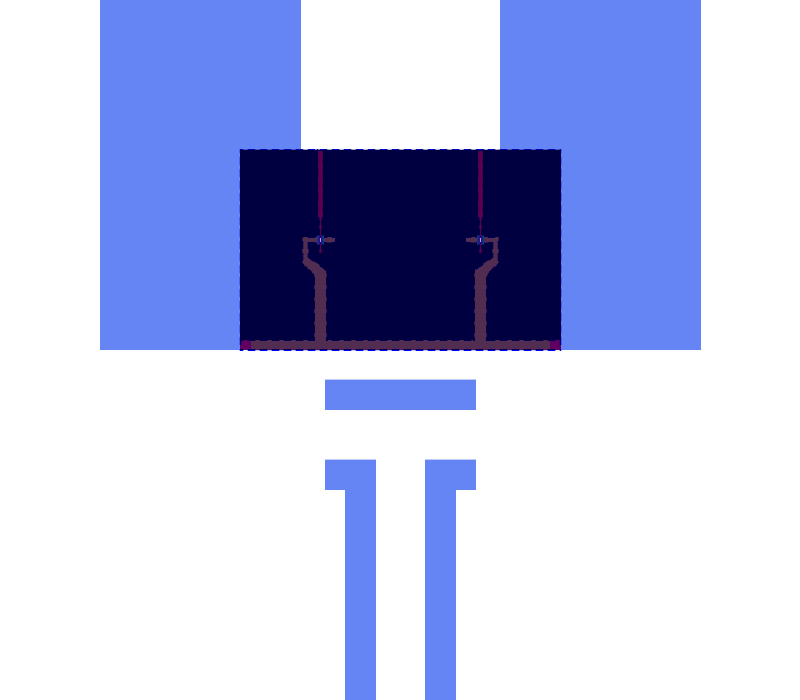

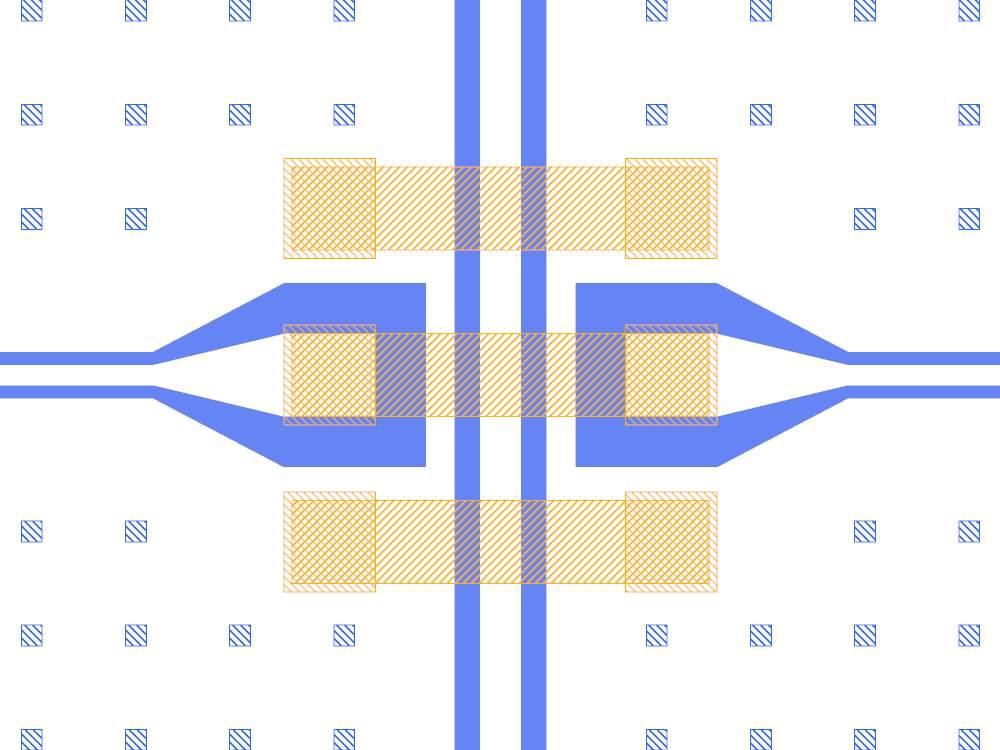

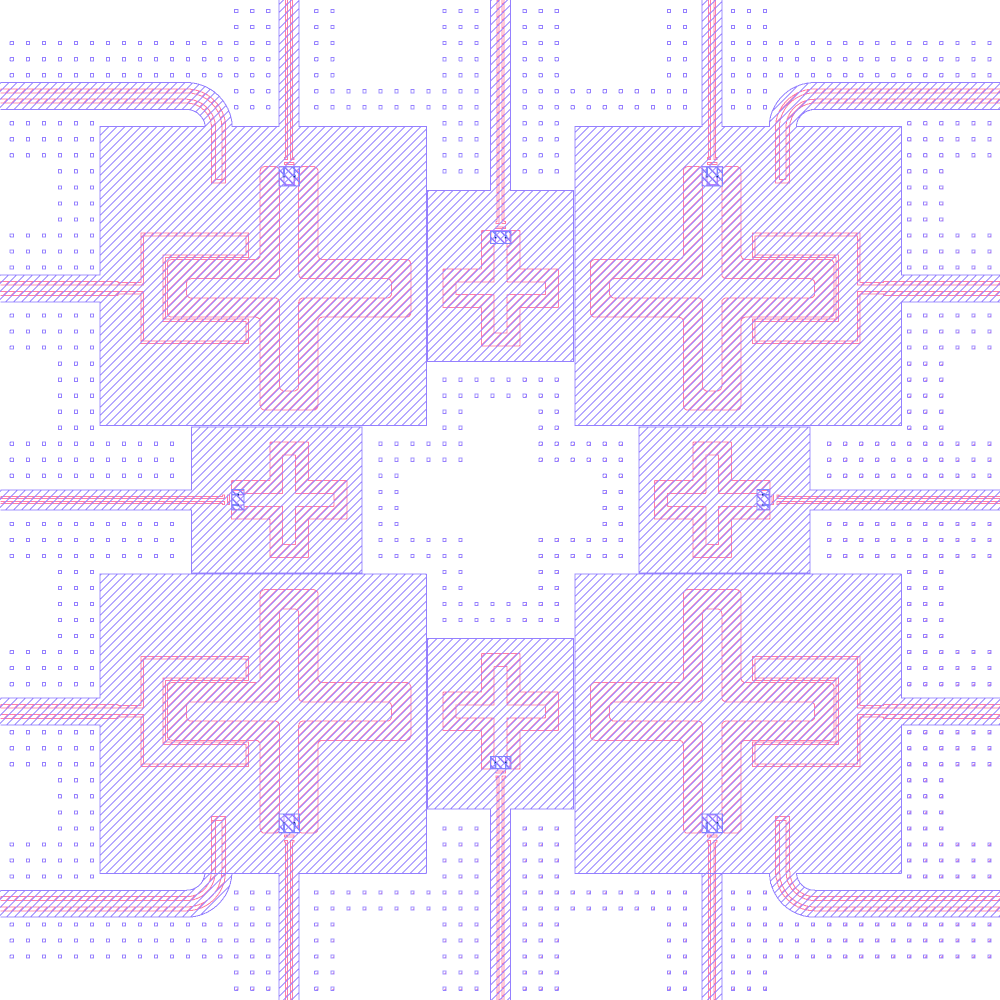

In [20]:
snap(d, OUT / "google_tc_2x2.png", size=(1500, 1500))
snap(d, OUT / "google_tc_2x2_plaquette.png", box=(X0 - S - 450, Y0 - S - 450, X0 + S + 450, Y0 + S + 450),
     size=(1400, 1400), width=560)
snap(d, OUT / "google_tc_2x2_squid.png", box=(X0 - 40, Y0 - S - 125, X0 + 40, Y0 - S - 55), size=(800, 700), width=320)
snap(d, OUT / "google_tc_2x2_bridge.png", box=(XF - 120, Y0 - 90, XF + 120, Y0 + 90), size=(1000, 750), width=360)
snap_file(Path("build") / "google_tc_2x2_fab.oas", OUT / "google_tc_2x2_cheese.png",
          box=(X0 - S - 450, Y0 - S - 450, X0 + S + 450, Y0 + S + 450), size=(1000, 1000), width=400);

## 15 · Summary

- **Matches the source:** the plaquette topology (a tunable coupler on every bond), the cell's off point on every bond
  (f_c ≈ 7.77 GHz), the idle ZZ below 0.1 MHz, f_q at Sycamore's idle, the staggered readouts (≈ 1.6 % below
  their targets: Nb kinetic inductance now in the LOM, step 9 a).
- **Changed by the PDK:** trilayer SQUIDs at R_n ≈ 40 kΩ (α −237 MHz, Sycamore −208 MHz); the 10 mm die and frame;
  pads 100 µm from the edges (the hangers placed by position, `near=`); the PDK band cheese (no original exists); planar wiring with two airbridges instead of
  Sycamore's flip-chip.
- **Open PDK design warnings:** none (every SQUID's parallel R_n 40.2 kΩ is in the window). The FEM jobs are
  exported, not solved (`RUN_FEM = False`).
- **Known limits:** the plaquette is simulated bond by bond (QuCat's symbolic solver stops at 8 junctions); the
  coupling capacitances are CPS estimates until the `plaquette` Q3D job has run.